# TLM Bridging -- Colab variant (TLM-XS / TLM-S / TLM-M)


# Cell 1 -- Imports & Device

In [3]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

import sys, os, re, json, math, functools
from pathlib import Path

### The name the project is saved in Google drive
PROJECT_NAME="TLM_V03"

DRIVE_ROOT = Path(f'/content/drive/MyDrive/{PROJECT_NAME}')
assert DRIVE_ROOT.exists(), f"{DRIVE_ROOT} not found -- upload the project to Drive first (see markdown above)"
sys.path.insert(0, str(DRIVE_ROOT))

from src.model_config import ModelConfig, count_parameters
from src.model_variants import TLM_S
from src.tokenizer import TLM_Tokenizer
from src.data_set import make_sft_sr, apply_sr, split_lines_by_newline, join_lines
from src.data_set.bridging_corruption import make_bridge_sr  # not re-exported from data_set/__init__.py
from src.data_loaders import PrecomputedBridgingDataset, collate_sft
from src.training import run_epoch, validate, make_scheduler, compute_loss, compute_loss_free_pgen, compute_loss_label_smoothed

import torch
from torch.utils.data import DataLoader
import numpy as np
import random

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.set_float32_matmul_precision("high")
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}  |  PyTorch: {torch.__version__}")


Mounted at /content/drive
[training.py] SRC_VERSION = role-aware-pgen-v4-intuitive-last
[calibration_training.py] SRC_VERSION = calibration-selfrollout-v2-batched
[confidence_head_training.py] SRC_VERSION = confidence-head-v1
Device: cuda  |  PyTorch: 2.11.0+cu128


## Cell 2 -- Model Variant & Paths

In [4]:
# -- MODEL VARIANT -- set every run -- must match the pretrain checkpoint you're bridging from
PRETRAIN_IS_UNBIASED_COPY = True  # True for the reported results from the thesis else false will fall back to the roll aware pgen.
MODEL_VARIANT = "S"   # "XXS","XS", "S", or "M"/ XXS was done as Spass
assert MODEL_VARIANT in ("XXS","XS", "S", "M"), f"MODEL_VARIANT must be 'XXS','XS', 'S' or 'M', got {MODEL_VARIANT!r}"
if PRETRAIN_IS_UNBIASED_COPY:
    _variant_prefix = f"tlm_{MODEL_VARIANT.lower()}_pretrain_unbiased_copy"
else:
    _variant_prefix = f"tlm_{MODEL_VARIANT.lower()}"

BRIDGING_DIR   = DRIVE_ROOT / "data" / "bridging" # If folder structure changes point this to the new dataset
TRAIN_IDS_PATH = BRIDGING_DIR / "bridging_train_ids.jsonl"
VAL_IDS_PATH   = BRIDGING_DIR / "bridging_val_ids.jsonl"
VAL_TEXT_PATH  = BRIDGING_DIR / "bridging_val.jsonl"   

TOKENIZER_PATH = str(DRIVE_ROOT / "src" / "tokenizer" / "tokenizer_tlm_small.json")

## Set the paths for the pretraining and bridging checkpoints
PRETRAIN_CKPT_DIR = (
    DRIVE_ROOT / "data" / "checkpoints" / f"tlm_{MODEL_VARIANT.lower()}_pretrain_unbiased_copy"
    if PRETRAIN_IS_UNBIASED_COPY else
    DRIVE_ROOT / "data" / "checkpoints" / f"{_variant_prefix}_pretrain"
)

BRIDGING_CKPT_DIR = DRIVE_ROOT / "data" / "checkpoints" / f"{_variant_prefix}_bridging"
BRIDGING_CKPT_DIR.mkdir(parents=True, exist_ok=True)

print(f"MODEL_VARIANT={MODEL_VARIANT!r}  PRETRAIN_CKPT_DIR={PRETRAIN_CKPT_DIR}  BRIDGING_CKPT_DIR={BRIDGING_CKPT_DIR}")
for p in (TRAIN_IDS_PATH, VAL_IDS_PATH, VAL_TEXT_PATH):
    print(f"  {'OK' if p.exists() else 'MISSING'}  {p}")

MODEL_VARIANT='S'  PRETRAIN_CKPT_DIR=/content/drive/MyDrive/TLM_V03/data/checkpoints/tlm_s_pretrain_unbiased_copy  BRIDGING_CKPT_DIR=/content/drive/MyDrive/TLM_V03/data/checkpoints/tlm_s_pretrain_unbiased_copy_bridging
  OK  /content/drive/MyDrive/TLM_V03/data/bridging/bridging_train_ids.jsonl
  OK  /content/drive/MyDrive/TLM_V03/data/bridging/bridging_val_ids.jsonl
  OK  /content/drive/MyDrive/TLM_V03/data/bridging/bridging_val.jsonl


## Cell 3 -- Model Config, Tokenizer & Pretrained Checkpoint


In [ ]:
if MODEL_VARIANT == "XXS":
    config = ModelConfig(d_model=96, d_ff=384, n_encoder_layers=3, n_decoder_layers=3,
                         n_heads=3, tier_name="TLM_XXS", target_param_count=1_740_000)
elif MODEL_VARIANT == "XS":
    config = ModelConfig(d_model=128, d_ff=512, tier_name="TLM_XS", target_param_count=2_420_000)
elif MODEL_VARIANT == "S":
    config = ModelConfig()
else:  # "M" -- 256 d_model / 1024 d_ff, same 4+4 layers / 4 heads / 6 task types as S
    config = ModelConfig(d_model=256, d_ff=1024, tier_name="TLM_M", target_param_count=9_500_000)
print(config)
print(f"Estimated params: {config.estimated_params()/1e6:.2f}M")

PAD_ID = config.special_token_ids["pad"]

# -- LABEL SMOOTHING -- must match whatever the pretrain checkpoint being loaded below was
# Was tried on a role aware pgen XS checkpoint (tlm_xs_pretrain) and found to be harmful, so the reported results in the thesis
# LABEL_SMOOTHING = 0.1   # only used when MODEL_VARIANT == "XS"; set to 0.0 if bridging from
#                         # the LS=0 baseline run (tlm_xs_pretrain_ls0) instead.
# if MODEL_VARIANT == "XXS":
#     LOSS_FN = functools.partial(compute_loss_label_smoothed, smoothing=LABEL_SMOOTHING)
#     print(f"Loss: compute_loss_label_smoothed (smoothing={LABEL_SMOOTHING})")

## Change to elif if you decide to try label smoothing
if PRETRAIN_IS_UNBIASED_COPY:
    ### This is the approach reported in results
    LOSS_FN = compute_loss_free_pgen
    print("Loss: compute_loss_free_pgen (matches tlm_m_pretrain_unbiased_copy's pretrain objective)")
else:
    # LOSS_FN = compute_loss  # old approach -- role-aware SEARCH/REPLACE target;
    LOSS_FN = compute_loss
    print("Loss: compute_loss (unchanged S/M behavior)")

tokenizer = TLM_Tokenizer(vocab_size=config.vocab_size)
tokenizer.load(TOKENIZER_PATH)
print(f"Tokenizer loaded from {TOKENIZER_PATH}  |  vocab_size = {tokenizer.tokenizer.get_vocab_size()}")

if PRETRAIN_IS_UNBIASED_COPY:
    _ckpts = sorted(PRETRAIN_CKPT_DIR.glob(f"tlm_{MODEL_VARIANT.lower()}_pretrain_unbiased_copy_epoch_*_val*.pt"))
else:    
    _ckpts = sorted(PRETRAIN_CKPT_DIR.glob(f"{_variant_prefix}_pretrain_epoch_*_val*.pt"))
    assert _ckpts, (f"No checkpoints found in {PRETRAIN_CKPT_DIR} -- fix PRETRAIN_CKPT_DIR above "
                    "to point at wherever the Colab pretrain run actually saved its checkpoints.")

def _val_loss_from_name(p):
    m = re.search(r"val([0-9.]+)\.pt$", p.name)
    return float(m.group(1)) if m else float("inf")

PRETRAIN_CKPT_PATH = min(_ckpts, key=_val_loss_from_name) ## Change this to a hard coded checkpoint if you want to play around and try different checkpoints
print(f"Found {len(_ckpts)} checkpoint(s) in {PRETRAIN_CKPT_DIR}")
print(f"Using: {PRETRAIN_CKPT_PATH.name}")

model = TLM_S(config)  # instantiate the model with the config for the chosen variant, the name says S as a leftover. 
                        # TLM_S is the model class it can be used for all variants from XS to M
_state = torch.load(PRETRAIN_CKPT_PATH, map_location=device)
model.load_state_dict(_state["model"])
model.to(device)
print(f"Loaded pretrain checkpoint: epoch {_state.get('epoch')}  val_loss {_state.get('val_loss')}  "
      f"val_pgen {_state.get('val_pgen')}")
print(f"Model params: {count_parameters(model)/1e6:.3f}M")


[Config] Estimated params: embed=1920000, enc_attn=589824, dec_attn=1179648, enc_ffn=1183488, dec_ffn=1183488, enc_ln=3456, dec_ln=4992, task_emb=4608, copy_head=193, head=0
ModelConfig [TLM_S]
  d_model=192, n_heads=4
  Encoder: 4L  Decoder: 4L  FFN: 768
  Estimated: 6.07M params  (target: 5.00M)
  Vocab: 10000  MaxSeq: 1024  TaskTypes: 6  WeightTie: True
[Config] Estimated params: embed=1920000, enc_attn=589824, dec_attn=1179648, enc_ffn=1183488, dec_ffn=1183488, enc_ln=3456, dec_ln=4992, task_emb=4608, copy_head=193, head=0
Estimated params: 6.07M
Loss: compute_loss_free_pgen (matches tlm_m_pretrain_unbiased_copy's pretrain objective)
Tokenizer loaded from /content/drive/MyDrive/TLM_V03/src/tokenizer/tokenizer_tlm_small.json  |  vocab_size = 10000
Found 20 checkpoint(s) in /content/drive/MyDrive/TLM_V03/data/checkpoints/tlm_s_pretrain_unbiased_copy
Using: tlm_s_pretrain_unbiased_copy_epoch_20_val0.3054.pt
[tlm_s.py] Initialized TLM_S model variant with 6069697 parameters
Loaded pret

## Cell 4 -- Bridging Datasets & DataLoaders

In [8]:
train_ds = PrecomputedBridgingDataset(TRAIN_IDS_PATH)
val_ds   = PrecomputedBridgingDataset(VAL_IDS_PATH)
print(f"train: {len(train_ds):,} samples")
print(f"val:   {len(val_ds):,} samples")

BATCH_SIZE  = 32  # I only tried this, other settings can be tried such as a smaller/biggger batch size
NUM_WORKERS = 2 if torch.cuda.is_available() else 0
_PIN        = torch.cuda.is_available()
_collate    = lambda b: collate_sft(b, PAD_ID)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          collate_fn=_collate, num_workers=NUM_WORKERS, pin_memory=_PIN)
val_loader   = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False,
                          collate_fn=_collate, num_workers=NUM_WORKERS, pin_memory=_PIN)
print(f"train batches: {len(train_loader)}  |  val batches: {len(val_loader)}  |  device: {device}")

_b = next(iter(train_loader))
print("sample batch shapes:", {k: tuple(v.shape) for k, v in _b.items()})
print("sample task_ids:", _b["task_ids"][:8].tolist())


train: 71,250 samples
val:   3,750 samples
train batches: 2227  |  val batches: 118  |  device: cuda
sample batch shapes: {'enc_ids': (32, 485), 'enc_attn': (32, 485), 'dec_ids': (32, 411), 'task_ids': (32,)}
sample task_ids: [5, 5, 3, 5, 1, 1, 4, 2]


## Cell 5 -- Training Setup

In [9]:
## Also only tried this setting, maybe something differnt would turn out to have better results
EPOCHS       = 4
LR           = 3e-5
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.05
GRAD_CLIP    = 1.0
PATIENCE     = 2      # early stopping on val NLL -- short run, stop fast if it's not helping

steps_per_epoch = len(train_loader)
total_steps     = steps_per_epoch * EPOCHS
warmup_steps    = int(total_steps * WARMUP_RATIO)

optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = make_scheduler(optimizer, warmup_steps, total_steps)

print(f"epochs={EPOCHS}  steps/epoch={steps_per_epoch}  total={total_steps}  "
      f"warmup={warmup_steps}  lr={LR}")


epochs=4  steps/epoch=2227  total=8908  warmup=445  lr=3e-05


## Cell 6 -- Train Loop (resumable)



In [10]:
RESUME_PATH = BRIDGING_CKPT_DIR / "last.pt" # Each epoch saves a last.pt after it ends
                                            # You can change this to a hard coded checkpoint if you want.
best_val       = float("inf")
best_ckpt_path = None
bad_epochs     = 0
history        = []
start_epoch    = 1

if RESUME_PATH.exists():
    print(f"Resuming from {RESUME_PATH}")
    _ckpt = torch.load(RESUME_PATH, map_location=device)
    model.load_state_dict(_ckpt["model"])
    optimizer.load_state_dict(_ckpt["optimizer"])
    scheduler.load_state_dict(_ckpt["scheduler"])
    start_epoch    = _ckpt["epoch"] + 1
    best_val       = _ckpt["best_val"]
    bad_epochs     = _ckpt["bad_epochs"]
    best_ckpt_path = Path(_ckpt["best_ckpt_path"]) if _ckpt.get("best_ckpt_path") else None
    history        = _ckpt["history"]
    print(f"  resuming at epoch {start_epoch}  |  best_val so far {best_val:.4f}  |  "
          f"bad_epochs {bad_epochs}/{PATIENCE}")
    if start_epoch > EPOCHS:
        print("  start_epoch already past EPOCHS -- nothing left to do (bump EPOCHS above to continue).")
else:
    print("No last.pt found -- starting fresh bridging run")

for epoch in range(start_epoch, EPOCHS + 1):
    print(f"\n=== Epoch {epoch}/{EPOCHS} ===")
    tr = run_epoch(model, train_loader, optimizer, scheduler, device, PAD_ID,
                   epoch=epoch, sampler=None, ss_enabled=False,
                   grad_clip=GRAD_CLIP, log_every=200, loss_fn=LOSS_FN)
    va = validate(model, val_loader, device, PAD_ID, log_every=40, loss_fn=LOSS_FN)
    print(f"epoch {epoch}: train_loss {tr['loss']:.4f} train_nll {tr['nll_end']:.4f} p_gen {tr['p_gen']:.3f} | "
          f"val_nll {va['nll']:.4f} val_pgen {va['p_gen']:.3f}")
    history.append({"epoch": epoch,
                    "train_loss": tr["loss"], "train_nll": tr["nll_end"], "train_pgen": tr["p_gen"],
                    "val_nll":    va["nll"],  "val_pgen":  va["p_gen"]})

    if va["nll"] < best_val:
        best_val = va["nll"]; bad_epochs = 0
        best_ckpt_path = BRIDGING_CKPT_DIR / f"{_variant_prefix}_bridging_epoch_{epoch}_val{va['nll']:.4f}.pt"
        torch.save({"model": model.state_dict(), "epoch": epoch,
                    "val_nll": va["nll"], "val_pgen": va["p_gen"]}, best_ckpt_path)
        print(f"  saved best -> {best_ckpt_path.name}")
    else:
        bad_epochs += 1
        print(f"  no improvement ({bad_epochs}/{PATIENCE})")

    torch.save({
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "scheduler": scheduler.state_dict(),
        "epoch": epoch,
        "best_val": best_val,
        "bad_epochs": bad_epochs,
        "best_ckpt_path": str(best_ckpt_path) if best_ckpt_path else None,
        "history": history,
    }, RESUME_PATH)

    if bad_epochs >= PATIENCE:
        print("early stopping.")
        break

print(f"\nbest val_nll: {best_val:.4f}")


No last.pt found -- starting fresh bridging run

=== Epoch 1/4 ===
    step     0 | loss 7.7572 | nll 6.9404 | p_gen 0.713 | p_samp 0.00 | lr 1.35e-07
    step   200 | loss 1.8362 | nll 1.3628 | p_gen 0.527 | p_samp 0.00 | lr 1.36e-05
    step   400 | loss 1.0813 | nll 0.6983 | p_gen 0.577 | p_samp 0.00 | lr 2.71e-05
    step   600 | loss 0.8955 | nll 0.5717 | p_gen 0.630 | p_samp 0.00 | lr 3.00e-05
    step   800 | loss 0.7750 | nll 0.4270 | p_gen 0.636 | p_samp 0.00 | lr 2.99e-05
    step  1000 | loss 0.7668 | nll 0.4429 | p_gen 0.600 | p_samp 0.00 | lr 2.97e-05
    step  1200 | loss 0.7313 | nll 0.4184 | p_gen 0.647 | p_samp 0.00 | lr 2.94e-05
    step  1400 | loss 0.6380 | nll 0.3578 | p_gen 0.643 | p_samp 0.00 | lr 2.91e-05
    step  1600 | loss 0.6226 | nll 0.3372 | p_gen 0.624 | p_samp 0.00 | lr 2.87e-05
    step  1800 | loss 0.5824 | nll 0.3282 | p_gen 0.643 | p_samp 0.00 | lr 2.82e-05
    step  2000 | loss 0.5653 | nll 0.3059 | p_gen 0.677 | p_samp 0.00 | lr 2.77e-05
    step 

## Cell 7 -- Training Curves

history saved -> /content/drive/MyDrive/TLM_V03/data/checkpoints/tlm_s_pretrain_unbiased_copy_bridging/training_history.json


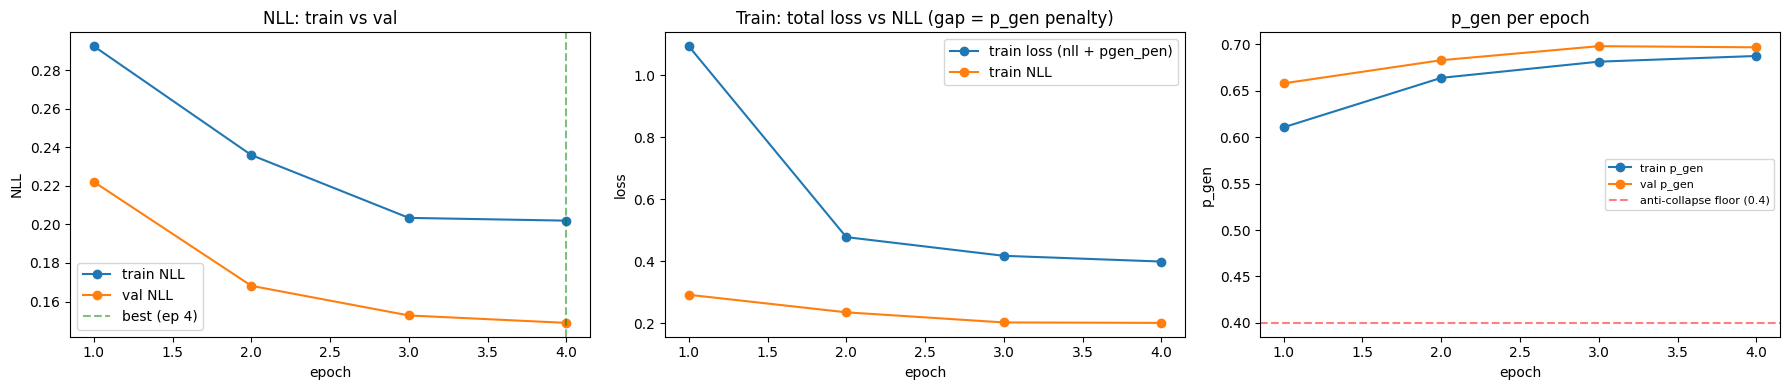

curves saved -> /content/drive/MyDrive/TLM_V03/data/checkpoints/tlm_s_pretrain_unbiased_copy_bridging/training_curves.png


In [11]:
import matplotlib.pyplot as plt

history_path = BRIDGING_CKPT_DIR / "training_history.json"
with open(history_path, "w") as f:
    json.dump(history, f, indent=2)
print(f"history saved -> {history_path}")

epochs_x   = [h["epoch"]      for h in history]
train_loss = [h["train_loss"] for h in history]
train_nll  = [h["train_nll"]  for h in history]
val_nll    = [h["val_nll"]    for h in history]
train_pgen = [h["train_pgen"] for h in history]
val_pgen   = [h["val_pgen"]   for h in history]
best_ep    = epochs_x[val_nll.index(min(val_nll))]

fig, axes = plt.subplots(1, 3, figsize=(18, 4))

ax1 = axes[0]
ax1.plot(epochs_x, train_nll, marker="o", label="train NLL")
ax1.plot(epochs_x, val_nll,   marker="o", label="val NLL")
ax1.axvline(x=best_ep, color="green", linestyle="--", alpha=0.5, label=f"best (ep {best_ep})")
ax1.set_xlabel("epoch"); ax1.set_ylabel("NLL")
ax1.set_title("NLL: train vs val"); ax1.legend()

ax2 = axes[1]
ax2.plot(epochs_x, train_loss, marker="o", label="train loss (nll + pgen_pen)")
ax2.plot(epochs_x, train_nll,  marker="o", label="train NLL")
ax2.set_xlabel("epoch"); ax2.set_ylabel("loss")
ax2.set_title("Train: total loss vs NLL (gap = p_gen penalty)"); ax2.legend()

ax3 = axes[2]
ax3.plot(epochs_x, train_pgen, marker="o", label="train p_gen")
ax3.plot(epochs_x, val_pgen,   marker="o", label="val p_gen")
if PRETRAIN_IS_UNBIASED_COPY:
    # New approach: no SEARCH/REPLACE role target for this run -- only the
    # anti-collapse floor (must match training.py's PGEN_FLOOR).
    ax3.axhline(y=0.4, color="red", linestyle="--", alpha=0.5, label="anti-collapse floor (0.4)")
else:
    # Old approach -- role-aware SR targets, not used for the unbiased-copy run.
    ax3.axhline(y=0.8, color="green", linestyle="--", alpha=0.5, label="SEARCH target (0.8)")
    ax3.axhline(y=0.2, color="gray",  linestyle="--", alpha=0.5, label="REPLACE target (0.2)")
ax3.set_xlabel("epoch"); ax3.set_ylabel("p_gen")
ax3.set_title("p_gen per epoch"); ax3.legend(fontsize=8)

plt.tight_layout()
plot_path = BRIDGING_CKPT_DIR / "training_curves.png"
plt.savefig(plot_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"curves saved -> {plot_path}")
